In [20]:
!pip install roboflow

from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)
project = rf.workspace("ziauddin-university").project("vehicle-detection-y7ocl")
version = project.version(13)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...


In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA available: True
GPU name: Tesla T4


In [3]:
import os
import yaml
from collections import Counter
from PIL import Image

data_yaml_path = "/kaggle/working/Vehicle-Detection-13/data.yaml"
with open(data_yaml_path) as f:
    data_cfg = yaml.safe_load(f)

base = os.path.dirname(data_yaml_path)
splits = {"train": "train/images", "valid": "valid/images", "test": "test/images"}

# 1. How big is the data?
for split, rel_path in splits.items():
    img_dir = os.path.join(base, rel_path)
    n_images = len([f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{split}: {n_images} images")

# 2. What does the data look like? (sample a few images' dimensions)
sample_img_dir = os.path.join(base, "train/images")
sample_files = os.listdir(sample_img_dir)[:5]
for f in sample_files:
    img = Image.open(os.path.join(sample_img_dir, f))
    print(f, img.size, img.mode)

# 3. Class distribution — how many instances of each class, per split
# (this reads YOLO .txt label files: each line = "class_id x y w h")
def get_class_distribution(label_dir, class_names):
    counter = Counter()
    for fname in os.listdir(label_dir):
        if not fname.endswith(".txt"):
            continue
        with open(os.path.join(label_dir, fname)) as f:
            for line in f:
                class_id = int(line.split()[0])
                counter[class_names[class_id]] += 1
    return counter

class_names = data_cfg["names"]
for split in ["train", "valid", "test"]:
    label_dir = os.path.join(base, split, "labels")
    dist = get_class_distribution(label_dir, class_names)
    print(f"\n{split} class distribution:")
    for cls, count in sorted(dist.items(), key=lambda x: -x[1]):
        print(f"  {cls}: {count}")

# 4. Missing/empty labels — images with no corresponding label file or empty label file
img_dir = os.path.join(base, "train/images")
label_dir = os.path.join(base, "train/labels")
img_stems = {os.path.splitext(f)[0] for f in os.listdir(img_dir)}
label_stems = {os.path.splitext(f)[0] for f in os.listdir(label_dir)}
missing = img_stems - label_stems
print(f"\nTrain images with NO label file: {len(missing)}")

empty_labels = [f for f in os.listdir(label_dir) if os.path.getsize(os.path.join(label_dir, f)) == 0]
print(f"Train label files that are empty (no boxes): {len(empty_labels)}")

train: 972 images
valid: 65 images
test: 99 images
Numan_-25-_jpg.rf.ec3f6bfe8ffd8fab7564324e3ae65997.jpg (1920, 1080) RGB
frame-3155_jpg.rf.bbe7f96173c78a3fd7cc2b010cbd9194.jpg (640, 640) RGB
Image_013314_jpg.rf.a37313f84b95039106da6eb8ea8aa4ab.jpg (640, 640) RGB
frame11250_jpg.rf.64e7f4b0bf0b17e749488157c651122a.jpg (1920, 1080) RGB
Navid_304_jpg.rf.ec8bd5a4d7196bf5d94b6dc47f4d6e29.jpg (1280, 720) RGB

train class distribution:
  Car: 11758
  Person: 8454
  Motor Cycle: 4024
  Rickshaw: 2484
  Truck: 938
  Bus: 900

valid class distribution:
  Car: 933
  Person: 773
  Motor Cycle: 288
  Rickshaw: 286
  Bus: 123
  Truck: 106

test class distribution:
  Person: 728
  Car: 552
  Motor Cycle: 459
  Rickshaw: 363
  Bus: 72
  Truck: 47

Train images with NO label file: 0
Train label files that are empty (no boxes): 0


In [4]:
train_files = os.listdir(os.path.join(base, "train/images"))[:10]
valid_files = os.listdir(os.path.join(base, "valid/images"))[:10]
print("Sample train filenames:", train_files)
print("Sample valid filenames:", valid_files)

Sample train filenames: ['Numan_-25-_jpg.rf.ec3f6bfe8ffd8fab7564324e3ae65997.jpg', 'frame-3155_jpg.rf.bbe7f96173c78a3fd7cc2b010cbd9194.jpg', 'Image_013314_jpg.rf.a37313f84b95039106da6eb8ea8aa4ab.jpg', 'frame11250_jpg.rf.64e7f4b0bf0b17e749488157c651122a.jpg', 'Navid_304_jpg.rf.ec8bd5a4d7196bf5d94b6dc47f4d6e29.jpg', 'frame1800_jpg.rf.312e8c31699ef0ef4b6e2685946dd25c.jpg', 'frame10500_jpg.rf.3f1e61060187119fb45d92eaa74fb53b.jpg', 'frame24000_jpg.rf.8e6f1d1f5aae4c4b6c57fd9d1a312e9e.jpg', 'frame-525_jpg.rf.a85ded40322245acef0b75f157b9b81f.jpg', 'frame11250_jpg.rf.dae8d90d0c630dd997ad69f841bf689b.jpg']
Sample valid filenames: ['Dipto_365_jpg.rf.4e5e24faba9f32b8f2c50389535a4ca7.jpg', 'Dipto_364_jpg.rf.e4aa02ac2b5c5d5b74fc7a679c4f7b1d.jpg', '69_jpg.rf.387c0839aa8f803d6cd5508c4fd2cb14.jpg', 'frame9000_jpg.rf.e6062531e34acb6770fd9508010229e6.jpg', 'Dipto_358_jpg.rf.0949dc925ba1207af52d57491d035c8f.jpg', 'Navid_113_jpg.rf.efc08cdc7fbd6d8bb772ace559b25867.jpg', 'frame1735_jpg.rf.b6c018483dba819567

In [5]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.7 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 4.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [6]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")   # start from COCO-pretrained weights, not from scratch

results = model.train(
    data="/kaggle/working/Vehicle-Detection-13/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,                 # GPU 0 — NOT the "cpu"/"cuda" string from config.yaml's detection section
    patience=15,               # early stopping: stop if val loss doesn't improve for 15 epochs
    project="vehicle_finetune",
    name="run1",
    exist_ok=True,
    save=True,
    save_period=5,             # checkpoint every 5 epochs (see Kaggle time-limit note below)

    # Turn OFF/reduce Ultralytics' built-in augmentation.
    # Roboflow already baked augmentation into these images (flip,
    # grayscale, brightness/saturation shifts, blur, noise — see your
    # dataset export notes). If Ultralytics ALSO applies its own heavy
    # augmentation on top of already-augmented images, you get
    # over-augmented, unrealistic training data, which typically hurts
    # convergence rather than helping it. We keep only mild built-in
    # augmentation and disable the ones Roboflow already covered.
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    fliplr=0.0,
    flipud=0.0,
    mosaic=0.5,     # keep mosaic at reduced probability — still useful for small object detection
    mixup=0.0,

    lr0=0.01,        # default initial learning rate, works well for fine-tuning yolov8n
    optimizer="auto",
    seed=42,          # fixed seed = reproducible results, important for your report
    verbose=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics 8.4.138 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Vehicle-Detection-13/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      2.53G      1.754       1.78      1.166        537        640: 100% ━━━━━━━━━━━━ 51/51 7.2it/s 7.1s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1it/s 0.7s0.9s
                   all         62       2352      0.404      0.332      0.286      0.141

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.53G      1.665      1.504      1.143        519        640: 100% ━━━━━━━━━━━━ 51/51 7.2it/s 7.1s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s1.0s
                   all         62       2352      0.416       0.38      0.337      0.165

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.53G      1.605      1.389      1.122        554        640: 100% ━━━━━━━━━━━━ 51/51 7.2it/s 7.0s0.2s
                 Class     Images  Instances  

In [8]:
import re

def base_name(fname):
    # Strips the "...rf.<hash>.jpg" suffix Roboflow appends, leaving the
    # original source image identifier (e.g. "frame33750_jpg")
    return re.sub(r'\.rf\.[0-9a-f]+\.jpg$', '', fname)

train_dir = os.path.join(base, "train/images")
valid_dir = os.path.join(base, "valid/images")
test_dir = os.path.join(base, "test/images")

train_bases = {base_name(f) for f in os.listdir(train_dir)}
valid_bases = {base_name(f) for f in os.listdir(valid_dir)}
test_bases = {base_name(f) for f in os.listdir(test_dir)}

print("train ∩ valid overlap:", len(train_bases & valid_bases))
print("train ∩ test overlap:", len(train_bases & test_bases))
print("valid ∩ test overlap:", len(valid_bases & test_bases))

train ∩ valid overlap: 11
train ∩ test overlap: 2
valid ∩ test overlap: 1


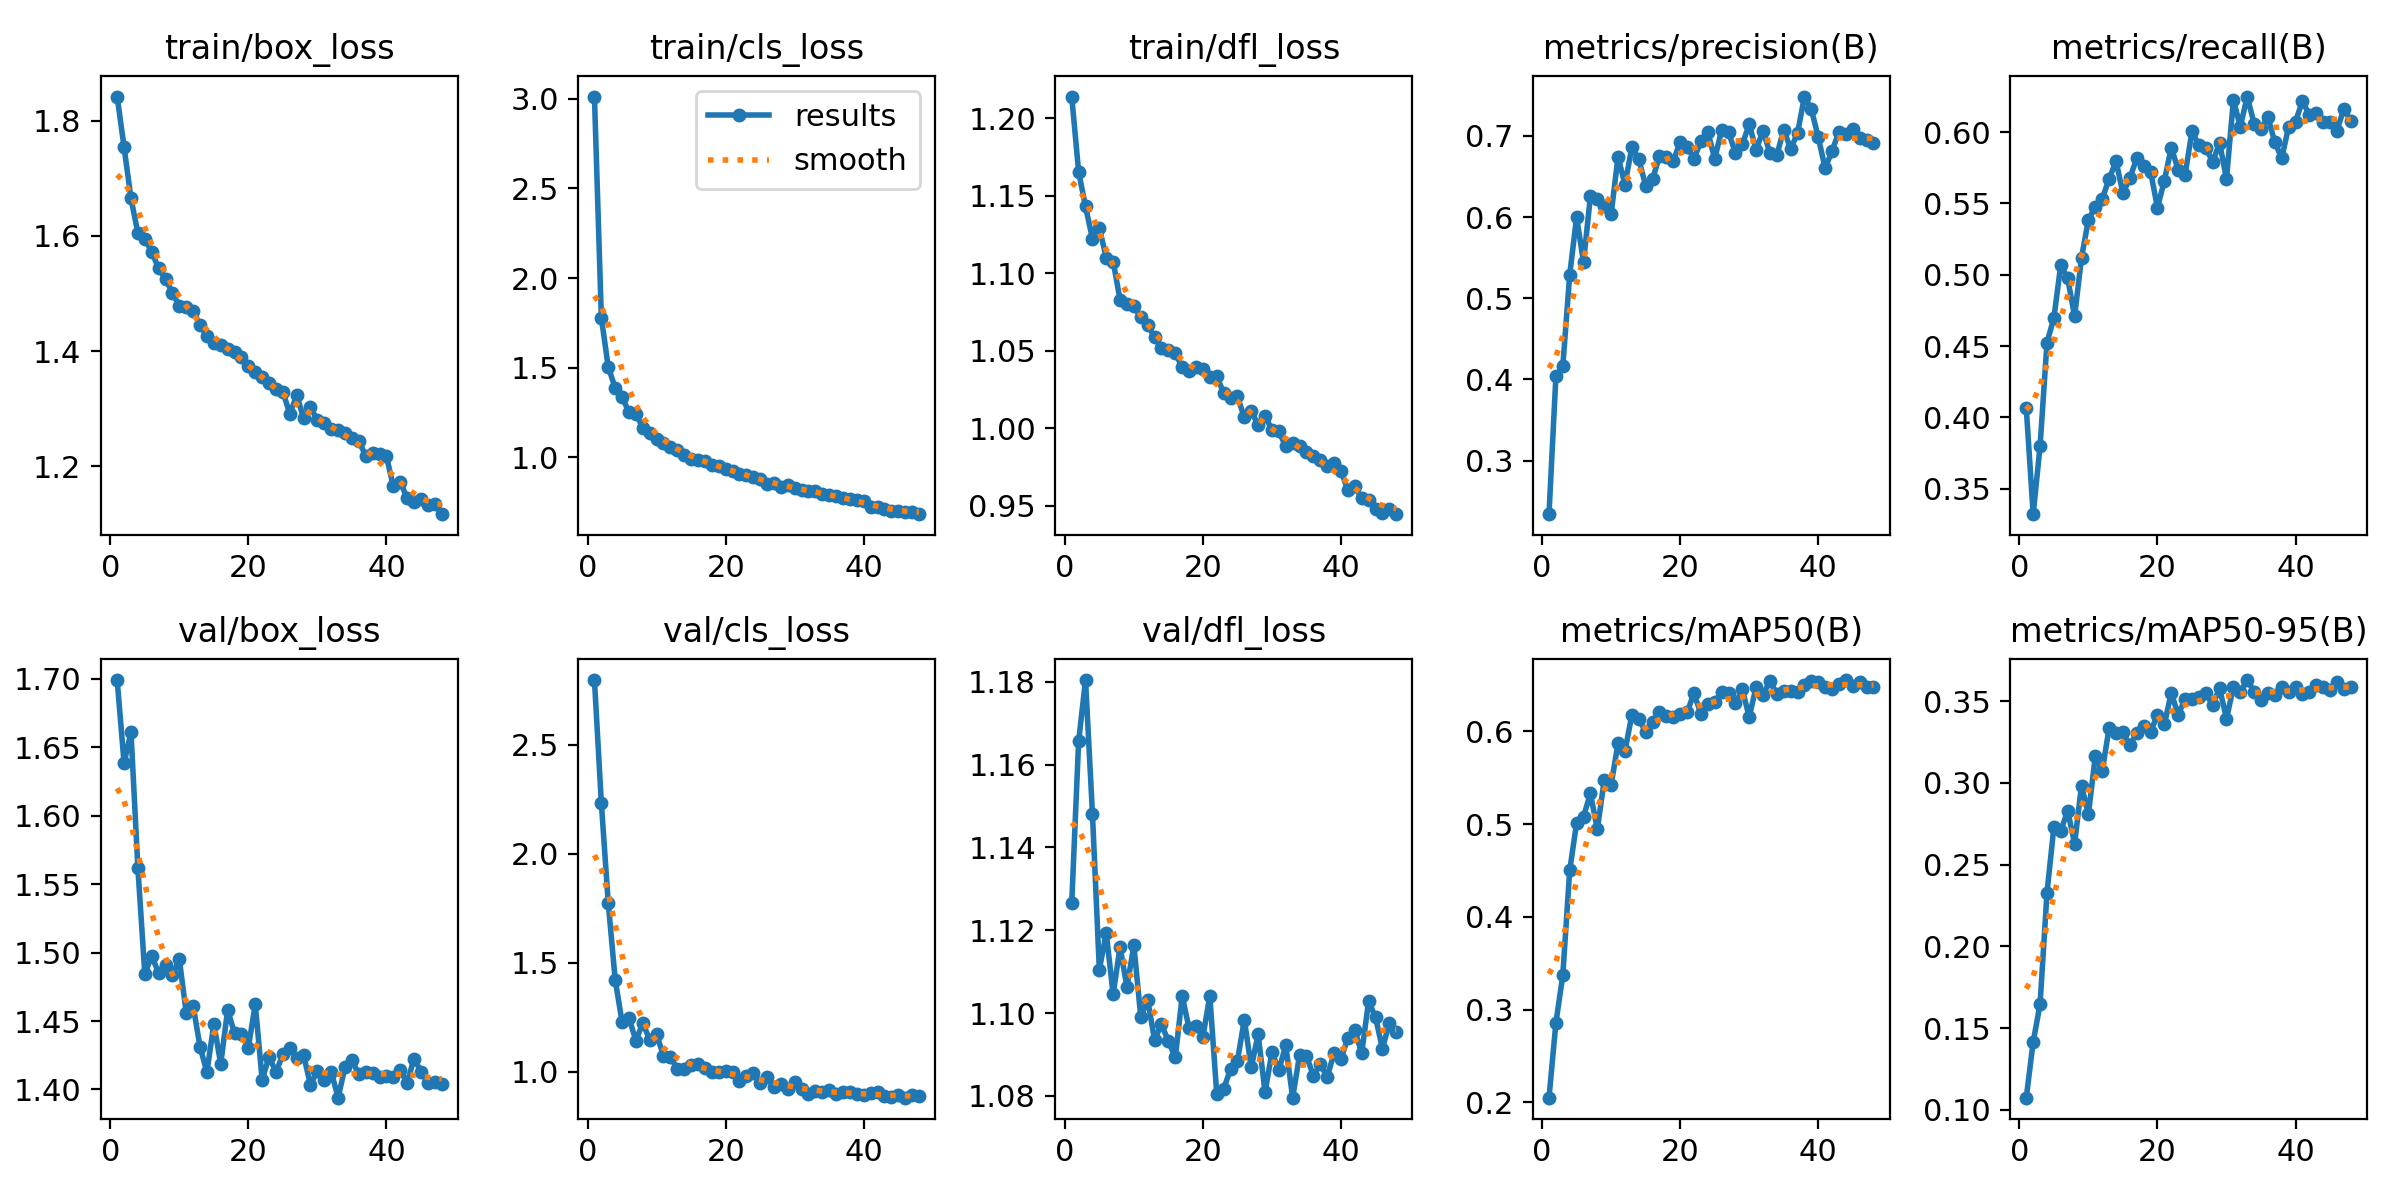

In [9]:
from IPython.display import Image as IPImage
IPImage(filename="/kaggle/working/runs/detect/vehicle_finetune/run1/results.png")

In [10]:
best_model = YOLO("/kaggle/working/runs/detect/vehicle_finetune/run1/weights/best.pt")

metrics = best_model.val(
    data="/kaggle/working/Vehicle-Detection-13/data.yaml",
    split="test"
)
print("Test mAP50:", metrics.box.map50)
print("Test mAP50-95:", metrics.box.map)

Ultralytics 8.4.138 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1570.8±1068.0 MB/s, size: 90.0 KB)
val: Scanning /kaggle/working/Vehicle-Detection-13/test/labels... 99 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 99/99 1.1Kit/s 0.1s
val: New cache created: /kaggle/working/Vehicle-Detection-13/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.5it/s 2.8s0.2s
                   all         99       2221      0.725      0.706      0.734      0.435
                   Bus         35         72      0.785      0.528      0.619      0.413
                   Car         93        552      0.812      0.904       0.92      0.626
           Motor Cycle         78        459       0.77      0.779      0.787      0.347
                Person         93        728  

In [11]:
import shutil
shutil.copy(
    "/kaggle/working/runs/detect/vehicle_finetune/run1/weights/best.pt",
    "/kaggle/working/best.pt"
)

'/kaggle/working/best.pt'

In [12]:
import os
print(os.path.exists("/kaggle/working/runs/detect/vehicle_finetune/run1/best.pt"))
print(os.path.exists("/kaggle/working/best.pt"))

False
True


In [21]:
import os
import json
import cv2
from ultralytics import YOLO

CUSTOM_NAMES = {0: "bus", 1: "car", 2: "motorcycle", 3: "person", 4: "rickshaw", 5: "truck"}
# COCO class id -> custom class id, only for classes present in BOTH label sets.
# 'rickshaw' has no COCO equivalent, so it's intentionally excluded rather
# than scored as a miss.
COCO_TO_CUSTOM = {2: 1, 3: 2, 5: 0, 7: 5, 0: 3}  # car, motorcycle, bus, truck, person

def yolo_txt_to_xyxy(label_path, w, h):
    boxes = []
    if not os.path.exists(label_path):
        return boxes
    with open(label_path) as f:
        for line in f:
            cls_id, cx, cy, bw, bh = (float(x) for x in line.split())
            cls_id = int(cls_id)
            boxes.append((cls_id, (cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h))
    return boxes

def iou(a, b):
    ax1, ay1, ax2, ay2 = a; bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    union = (ax2-ax1)*(ay2-ay1) + (bx2-bx1)*(by2-by1) - inter
    return inter / union if union > 0 else 0.0

def per_class_recall(model, img_dir, lbl_dir, class_map, allowed_gt_ids, conf=0.25, iou_thresh=0.5):
    hits = {c: 0 for c in allowed_gt_ids}
    totals = dict(hits)
    for fname in sorted(os.listdir(img_dir)):
        if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        img = cv2.imread(os.path.join(img_dir, fname))
        h, w = img.shape[:2]
        gt = yolo_txt_to_xyxy(os.path.join(lbl_dir, os.path.splitext(fname)[0] + ".txt"), w, h)

        result = model.predict(img, conf=conf, verbose=False)[0]
        preds = []
        for box in result.boxes:
            raw_cls = int(box.cls[0])
            mapped = class_map.get(raw_cls, raw_cls) if class_map else raw_cls
            if mapped not in totals:
                continue
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            preds.append((mapped, x1, y1, x2, y2))

        for gt_cls, gx1, gy1, gx2, gy2 in gt:
            if gt_cls not in allowed_gt_ids:
                continue
            totals[gt_cls] += 1
            if any(pc == gt_cls and iou((gx1,gy1,gx2,gy2),(px1,py1,px2,py2)) >= iou_thresh
                   for pc, px1, py1, px2, py2 in preds):
                hits[gt_cls] += 1

    return {CUSTOM_NAMES[c]: (hits[c]/totals[c] if totals[c] else None) for c in totals}

TEST_IMG = "/kaggle/working/Vehicle-Detection-13/test/images"
TEST_LBL = "/kaggle/working/Vehicle-Detection-13/test/labels"

pretrained = YOLO("yolov8n.pt")
finetuned = YOLO("/kaggle/working/best.pt")

pretrained_recall = per_class_recall(pretrained, TEST_IMG, TEST_LBL, COCO_TO_CUSTOM, set(COCO_TO_CUSTOM.values()))
finetuned_recall = per_class_recall(finetuned, TEST_IMG, TEST_LBL, {}, set(CUSTOM_NAMES.keys()))

os.makedirs("/kaggle/working/eval_report", exist_ok=True)
report = {"pretrained_recall": pretrained_recall, "finetuned_recall": finetuned_recall}
with open("/kaggle/working/eval_report/comparison.json", "w") as f:
    json.dump(report, f, indent=2)
print(json.dumps(report, indent=2))

{
  "pretrained_recall": {
    "bus": 0.5694444444444444,
    "car": 0.8532608695652174,
    "motorcycle": 0.3638344226579521,
    "person": 0.6634615384615384,
    "truck": 0.3404255319148936
  },
  "finetuned_recall": {
    "bus": 0.4722222222222222,
    "car": 0.907608695652174,
    "motorcycle": 0.8061002178649237,
    "person": 0.8063186813186813,
    "rickshaw": 0.9146005509641874,
    "truck": 0.3404255319148936
  }
}


In [23]:
import os
import shutil
from IPython.display import FileLink

RUN_DIR = "/kaggle/working/runs/detect/vehicle_finetune/run1"

if not os.path.isdir(RUN_DIR):
    print(f"Expected run directory not found: {RUN_DIR}")
    print("Contents of /kaggle/working/runs (if it exists):")
    if os.path.isdir("/kaggle/working/runs"):
        for root, dirs, files in os.walk("/kaggle/working/runs"):
            print(root)
    else:
        print("  /kaggle/working/runs does not exist -- this session never ran training.")
else:
    shutil.make_archive("/kaggle/working/phase3_artifacts", "zip", RUN_DIR)
    shutil.make_archive("/kaggle/working/eval_report", "zip", "/kaggle/working/eval_report")
    print("Zipped successfully.")

FileLink("phase3_artifacts.zip")

Zipped successfully.


/kaggle/working/phase3_artifacts.zip